# Weekly A&E demand and escalation briefing: spot check

## 1. Purpose, scope and what is simulated

This notebook is the spot check behind the design case study: the design run on Public Health
Scotland's real weekly A&E data. It loads and checks the data,
forecasts demand, runs the demand level and drift rules, and evaluates them. Sections 5 to 7, the
agents, the approval queue and the replay set, replay the live run's recorded model replies; no
language model runs in this notebook.

**What the demand level means.** The demand level shows demand unusually high for the time of year.
It is not pressure, need or priority. It is for adjusting front-door staffing inside rotas already
set: extra shifts, bank staff or holding leave.

**What the tool is for.** Aggregate operational planning for a hospital and a week. It is never for
ranking hospitals, justifying cuts or monitoring the 4-hour standard, and a person approves every
action it suggests.

| Input | Real or simulated | Where it comes from |
|---|---|---|
| Weekly unplanned attendances per hospital, and their national sum | Real | Public Health Scotland, weekly A&E activity, frozen by SHA-256, OGL |
| Attendances seen within 4 hours, and waits over 12 hours | Real | The same file; used only for the pressure match and the month chart, never to monitor the 4-hour standard |
| Scottish bank holidays | Real | GOV.UK bank-holidays JSON, frozen 24 Oct 2026, OGL |
| Simulated capacity | Simulated | Assumed: the 90th percentile of each hospital's own past demand in the same 13 weeks of the three previous years. A seasonal baseline of past demand, not beds or staff |
| The bands, 1.05, 1.10 and 1.15 times capacity | Our design, illustrative | Assumed: the structure of England's OPEL framework, where a score sets the level and people decide the actions, not its scale |
| Latch resets | Simulated | Assumed: recorded at each review prompt after 8 clear weeks, as the replay does; in use the unscheduled-care lead approves each one |
| The staffing actions by level and their reply deadlines | Our design, illustrative | Assumed: on the structure of OPEL Appendix F only, actions by level with an owner each, not its pressure actions; the deadlines are assumed |
| Staff acknowledgements of notifications | Simulated | Assumed: seeded stand-ins, not real replies, on the replay's clock, which starts at 10:00 on release day |
| The model's replies in sections 5 to 7 | Recorded | The live run's recordings, replayed exactly; no model runs in this notebook |

Every figure in this notebook is in-sample: the design was tuned in probes on the same 2015 to 2026
data that scores it.

In [1]:
# The Environment Setup tab's import check: NumPy, pandas and Matplotlib.
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydantic
import torch
from IPython.display import display
from pydantic import ValidationError

from ae_escalation import approval as ap
from ae_escalation import backtest as bt
from ae_escalation import briefs as br
from ae_escalation import config as cf
from ae_escalation import coordinator as co
from ae_escalation import data as dt
from ae_escalation import demo as dm
from ae_escalation import design as ds
from ae_escalation import evaluation as ev
from ae_escalation import gru
from ae_escalation import replay as rp
from ae_escalation import template as tp
from ae_escalation import timing as tm
from ae_escalation import tools as tl
from ae_escalation import units as un

print("Python", sys.version.split()[0])
print("NumPy", np.__version__)
print("pandas", pd.__version__)
print("Matplotlib", matplotlib.__version__)
print("torch", torch.__version__, "and Pydantic", pydantic.__version__)

Python 3.12.3
NumPy 2.5.4
pandas 3.0.6
Matplotlib 3.11.2
torch 2.14.1+cpu and Pydantic 2.14.1


In [2]:
DATA = Path("data")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
NAMES = {**dt.HOSPITAL_NAMES, "Scotland": "Scotland"}
BIG5 = ["S314H", "G405H", "G107H", "L308H", "F704H"]
REPLAY = list(ds.REPLAY)
MODEL_NAMES = {
    "seasonal_naive": "Seasonal naive",
    "ma4": "4-week moving average",
    "linear": "Linear",
    "gru": "GRU comparator",
    "naive_last_week": "Reference: last week's value",
    "linear_covid_masked": "Reference: linear, COVID weeks left out",
}
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)

# Neutral inks for text and axes; blue and orange are the first two slots
# of a palette checked for colour-blind readers.
INK, MUTED, GRID, BAND = "#0b0b0b", "#52514e", "#d8d7d2", "#ecebe7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)


def ci_cell(value, low, high):
    return f"{value:.2f} ({low:.2f} to {high:.2f})"

## 2. Data: load, verify, clean, flag

I follow the pattern AI Programming Foundations taught: load, verify, clean, flag and keep. The file
is checked against the SHA-256 in the manifest before it is read. Every row stays in the flagged
frame; a row left out of the series carries its reason, so it can still be counted and reported.
The series is weekly Unplanned attendances from the week ending 7 June 2015, after the
reconfiguration of Glasgow's emergency departments in May 2015.

In [3]:
manifest = {r.file: r for r in dt.read_manifest(DATA / "MANIFEST.tsv")}
sources = dt.verify_sources(DATA / "MANIFEST.tsv")
sources[["file", "licence", "access date", "bytes", "matches"]]

,file,licence,access date,bytes,matches
0,weekly_ae_activity_20261011.csv,UK Open Government Licence (OGL),2026-10-24,3829935,True
1,bank-holidays_20261024.json,Open Government Licence (OGL),2026-10-24,22207,True


In [4]:
CSV = "weekly_ae_activity_20261011.csv"
raw = dt.load_weekly(DATA / CSV, manifest[CSV].sha256)
quality = dt.quality_report(raw)
shape = {
    "rows": len(raw),
    "week endings": raw["WeekEndingDate"].nunique(),
    "first week ending": f"{raw['WeekEndingDate'].min():%d %b %Y}",
    "last week ending": f"{raw['WeekEndingDate'].max():%d %b %Y}",
    "hospitals": raw["TreatmentLocation"].nunique(),
    "health boards": raw["HBT"].nunique(),
}
pd.Series({**shape, **quality}, name="value").to_frame()

,value
rows,43185
week endings,608
first week ending,22 Feb 2015
last week ending,11 Oct 2026
hospitals,32
health boards,14
missing_values,0
duplicate_key_rows,2
duplicate_keys,"[(2015-05-03, G405H)]"
unplanned_zero_attendances,0


In [5]:
flagged = dt.flag_and_keep(raw)
in_series = flagged["in_series"]
print(
    f"{len(flagged):,} rows in the flagged frame: {in_series.sum():,} in the "
    f"series and {(~in_series).sum():,} set aside, each with its reason"
)
display(
    flagged.loc[~in_series, "exclusion_reason"]
    .value_counts()
    .rename("rows set aside")
    .to_frame()
)
unplanned = flagged[flagged["AttendanceCategory"] == "Unplanned"]
flags = ["duplicate_key", "site_outlier", "covid_period", "provisional"]
unplanned[flags].sum().rename("Unplanned rows flagged and kept").to_frame()

43,185 rows in the flagged frame: 17,790 in the series and 25,395 set aside, each with its reason


,rows set aside
exclusion_reason,
"not the Unplanned category, which is the series",24916
"before w/e 7 Jun 2015, the series' first week",479


,Unplanned rows flagged and kept
duplicate_key,2
site_outlier,48
covid_period,3270
provisional,90


In [6]:
wide = dt.series_from(flagged)
within4 = dt.series_from(flagged, value_col="NumberWithin4HoursEpisode")
sites = [c for c in wide.columns if c != "Scotland"]
print(
    f"{len(sites)} hospitals and the national series, {len(wide)} weeks from "
    f"w/e {wide.index[0]:%d %b %Y} to w/e {wide.index[-1]:%d %b %Y}; "
    f"no week missing: {bool(wide.notna().all().all())}"
)
national_all = dt.to_wide(raw, "TreatmentLocation").sum(axis=1)
outliers = dt.national_outliers(raw)
national_all[outliers].rename("national attendances").rename_axis(
    "national week flagged as an outlier and kept"
).to_frame()

30 hospitals and the national series, 593 weeks from w/e 07 Jun 2015 to w/e 11 Oct 2026; no week missing: True


,national attendances
national week flagged as an outlier and kept,
2016-12-25,22251.0
2017-12-17,29061.0
2018-03-04,21752.0
2020-03-29,11012.0
2020-04-05,11274.0
2020-04-12,11887.0
2021-12-26,18993.0
2023-01-15,20484.0
2025-12-28,22626.0


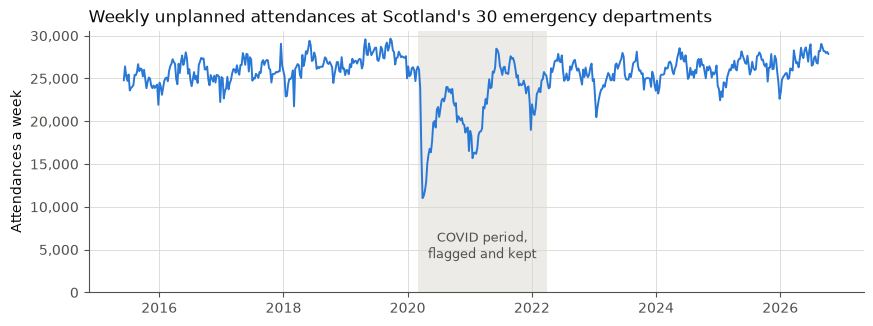

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axvspan(*dt.COVID_PERIOD, color=BAND, lw=0)
ax.plot(wide.index, wide["Scotland"], color=BLUE, lw=1.4)
ax.text(
    pd.Timestamp("2021-03-15"),
    4000,
    "COVID period,\nflagged and kept",
    color=MUTED,
    ha="center",
    fontsize=9,
)
ax.set_title(
    "Weekly unplanned attendances at Scotland's 30 emergency departments",
    loc="left",
    color=INK,
)
ax.set_ylabel("Attendances a week")
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
fig.savefig(
    FIGURES / "national_weekly_attendances.png", dpi=150, bbox_inches="tight"
)
plt.show()

**What is flagged and kept.** Nothing above is dropped from the file's frame. The weeks before
7 June 2015 and the two Glasgow sites that closed in May 2015 are set aside from the series with
their reason. One week at the Queen Elizabeth University Hospital, w/e 3 May 2015, has two rows per
category, which are summed, and it is before the series starts. The `All` category gains planned
attendances from November 2020, so the series is `Unplanned`, which continues the series as
published before 2025. The COVID period, March 2020 to March 2022, stays in the data, so the drift
latch and the re-selection are tested on a real shock; it is used only to split what is reported.
The newest three weeks are provisional, because PHS revises recent weeks slightly upward. The
outlier weeks stay in: three are Christmas weeks, which is why a demand brief names a bank holiday
that falls in a target week.

## 3. Forecasts and back-test

**Timing.** Each Tuesday release covers the week ending 9 days earlier. A forecast origin is the
latest week released, and the four release horizons are the next four week endings after the
release, which are data horizons 2 to 5. Every forecast, rule and tool works as of an origin and
sees only the weeks released by then; a unit test proves it.

In [8]:
origin = pd.Timestamp("2020-03-22")
print(
    f"Origin w/e {origin:%a %d %b %Y}, released "
    f"{tm.release_date(origin):%a %d %b %Y}"
)
pd.DataFrame(
    {
        "release horizon": tm.RELEASE_HORIZONS,
        "data horizon": [tm.data_horizon(k) for k in tm.RELEASE_HORIZONS],
        "week ending": tm.release_horizon_weeks(origin).strftime(
            "%a %d %b %Y"
        ),
    }
).set_index("release horizon")

Origin w/e Sun 22 Mar 2020, released Tue 31 Mar 2020


,data horizon,week ending
release horizon,,
1,2,Sun 05 Apr 2020
2,3,Sun 12 Apr 2020
3,4,Sun 19 Apr 2020
4,5,Sun 26 Apr 2020


**The back-test** is the rolling-origin back-test of the data test, fixed before any result was
seen, so its figures reproduce (D-EVAL-18): an origin every week, MAPE scored from w/e 7 January
2018, and 95% moving-block bootstrap intervals (8-week blocks, 2,000 resamples). Seasonal naive and
the 4-week moving average are the bars to beat from Deep Learning Systems. Linear is the trend line
from Statistical Analysis with four sine and cosine pairs, refitted at each origin on the trailing
156 weeks. The GRU comparator is Deep Learning Systems' recurrent forecaster: one layer of 16 units,
refitted each January, early stopping on the last 26 windows and the mean of three seeds, on the CPU.
The two reference rows are the data test's own: last week's value, and linear with the COVID weeks
left out, which uses hindsight. These first tables are at the data test's data horizons 1 to 4.

In [9]:
cal = tm.complete_weeks(wide.index[0], wide.index[-1] + pd.Timedelta(weeks=4))
baselines = bt.backtest_long(wide, bt.data_test_models(cal), H=4)
# The data test ran its GRU on six series; the design runs the GRU on the
# five named series only, so the three both share are reproduced here.
gru_dt = gru.gru_long(
    wide, ["Scotland", "S314H", "G405H"], H=4, first_target=bt.SCORE_START
)
backtest = pd.concat([baselines, gru_dt], ignore_index=True)
periods = bt.data_test_periods(backtest)
metrics = bt.error_summary(backtest, periods, series=["Scotland", *BIG5])


def mape_table(period, series="Scotland"):
    t = metrics[(metrics["period"] == period) & (metrics["series"] == series)]
    t = t.assign(
        cell=[ci_cell(*v) for v in t[["mape", "mape_lo", "mape_hi"]].values]
    )
    out = t.pivot(index="model", columns="h", values="cell")
    order = [m for m in MODEL_NAMES if m in out.index]
    return (
        out.loc[order]
        .rename(index=MODEL_NAMES)
        .rename(columns=lambda h: f"data horizon {h}")
    )


print("National MAPE %, 95% interval, outside March 2020 to March 2022")
mape_table("excl_covid")

National MAPE %, 95% interval, outside March 2020 to March 2022


h,data horizon 1,data horizon 2,data horizon 3,data horizon 4
model,,,,
Seasonal naive,3.77 (3.22 to 4.35),3.77 (3.22 to 4.35),3.77 (3.22 to 4.35),3.77 (3.22 to 4.35)
4-week moving average,3.17 (2.79 to 3.52),3.70 (3.23 to 4.13),4.10 (3.59 to 4.60),4.42 (3.87 to 4.95)
Linear,3.82 (3.06 to 4.75),4.05 (3.22 to 5.07),4.25 (3.36 to 5.32),4.41 (3.47 to 5.56)
GRU comparator,3.51 (2.98 to 4.16),3.62 (2.92 to 4.50),3.19 (2.79 to 3.64),3.77 (3.18 to 4.45)
Reference: last week's value,2.71 (2.42 to 3.00),3.66 (3.25 to 4.04),4.00 (3.50 to 4.44),4.35 (3.80 to 4.89)
"Reference: linear, COVID weeks left out",3.12 (2.63 to 3.67),3.28 (2.74 to 3.89),3.40 (2.81 to 4.07),3.50 (2.86 to 4.21)


In [10]:
print("National MAPE %, 95% interval, all weeks from w/e 7 Jan 2018")
mape_table("all")

National MAPE %, 95% interval, all weeks from w/e 7 Jan 2018


h,data horizon 1,data horizon 2,data horizon 3,data horizon 4
model,,,,
Seasonal naive,10.94 (7.28 to 15.34),10.94 (7.28 to 15.34),10.94 (7.28 to 15.34),10.94 (7.28 to 15.34)
4-week moving average,4.25 (3.34 to 5.56),5.27 (4.02 to 7.09),6.10 (4.60 to 8.26),6.81 (5.11 to 9.33)
Linear,8.03 (5.52 to 11.51),8.57 (5.88 to 12.28),9.04 (6.18 to 12.98),9.44 (6.45 to 13.60)
GRU comparator,8.00 (5.29 to 11.72),8.50 (5.64 to 12.39),7.67 (4.98 to 11.39),7.96 (5.29 to 11.74)
Reference: last week's value,3.17 (2.74 to 3.74),4.56 (3.73 to 5.76),5.38 (4.17 to 7.11),6.26 (4.73 to 8.47)
"Reference: linear, COVID weeks left out",10.64 (6.60 to 15.41),10.76 (6.70 to 15.52),10.85 (6.80 to 15.63),10.94 (6.89 to 15.72)


In [11]:
sub = metrics[(metrics["series"] == "Scotland") & metrics["h"].isin([1, 4])]
labels = {
    "pre_2018_feb2020": "Jan 2018 to Feb 2020",
    "covid_mar2020_mar2022": "Mar 2020 to Mar 2022",
    "post_apr2022_oct2026": "Apr 2022 to Oct 2026",
}
sub = sub[sub["period"].isin(labels)].pivot(
    index="model", columns=["period", "h"], values="mape"
)
print("National MAPE % by sub-period, data horizons 1 and 4")
display(
    sub.loc[[m for m in MODEL_NAMES if m in sub.index]]
    .rename(index=MODEL_NAMES, columns=labels)
    .round(2)
)
pairs = bt.paired_against(
    backtest,
    "seasonal_naive",
    {"excl_covid": periods["excl_covid"]},
    series=["Scotland"],
)
pairs = pairs[pairs["h"].isin([1, 4])].assign(
    difference=lambda p: [
        f"{d:+.2f} ({lo:+.2f} to {hi:+.2f})"
        for d, lo, hi in p[["mean_diff", "lo", "hi"]].values
    ]
)
print(
    "Paired difference in absolute % error against seasonal naive, national, "
    "outside the COVID period (negative is better)"
)
pairs.pivot(index="model", columns="h", values="difference").reindex(
    [m for m in MODEL_NAMES if m in set(pairs["model"])]
).rename(index=MODEL_NAMES, columns=lambda h: f"data horizon {h}")

National MAPE % by sub-period, data horizons 1 and 4


period                                  Jan 2018 to Feb 2020       Mar 2020 to Mar 2022        Apr 2022 to Oct 2026      
h                                                          1     4                    1      4                    1     4
model                                                                                                                    
Seasonal naive                                          4.17  4.17                33.90  33.90                 3.58  3.58
4-week moving average                                   3.04  3.79                 7.71  14.46                 3.23  4.72
Linear                                                  2.71  2.94                21.52  25.55                 4.34  5.11
GRU comparator                                          3.12  2.99                22.37  21.36                 3.69  4.14
Reference: last week's value                            2.74  3.99                 4.66  12.36                 2.69  4.52
Reference: linear, COVID weeks left out                 2.71  2.94                34.71  34.73                 3.32  3.77

Paired difference in absolute % error against seasonal naive, national, outside the COVID period (negative is better)


h,data horizon 1,data horizon 4
model,,
4-week moving average,-0.60 (-1.27 to -0.02),+0.65 (-0.15 to +1.36)
Linear,+0.05 (-0.86 to +1.06),+0.65 (-0.42 to +1.84)
GRU comparator,-0.26 (-0.89 to +0.40),+0.00 (-0.70 to +0.77)
Reference: last week's value,-1.06 (-1.67 to -0.51),+0.58 (-0.22 to +1.26)
"Reference: linear, COVID weeks left out",-0.65 (-1.24 to -0.10),-0.27 (-0.97 to +0.42)


In [12]:
five = metrics[
    (metrics["period"] == "excl_covid")
    & metrics["series"].isin(BIG5)
    & metrics["h"].isin([1, 4])
].pivot(index="series", columns=["model", "h"], values="mape")
five.index = [f"{NAMES[s]} ({s})" for s in five.index]
print(
    "Five large adult EDs, MAPE % at data horizons 1 and 4, outside the "
    "COVID period. The GRU runs only on the two of them in the replay set."
)
five = five.reindex(columns=list(MODEL_NAMES), level=0)
display(five.round(2).rename(columns=MODEL_NAMES, level=0))
sizes = bt.site_sizes(wide)
bands, size_corr = bt.size_bands(backtest, sizes, periods["excl_covid"])
print(
    f"Correlation of log size with log seasonal naive MAPE at horizon 1: "
    f"{size_corr:.2f}"
)
bands.round(1)

Five large adult EDs, MAPE % at data horizons 1 and 4, outside the COVID period. The GRU runs only on the two of them in the replay set.


model                                                 Seasonal naive       4-week moving average       Linear        \
h                                                                  1     4                     1     4      1     4   
Victoria Hospital (F704H)                                       6.02  6.02                  3.77  4.95   4.85  5.50   
Glasgow Royal Infirmary (G107H)                                 4.94  4.94                  3.71  4.39   4.89  5.58   
Queen Elizabeth University Hospital (G405H)                     4.62  4.62                  3.11  3.75   3.81  4.22   
University Hospital Wishaw (L308H)                              5.84  5.84                  3.96  5.08   4.78  5.41   
Royal Infirmary of Edinburgh at Little France (S314H)           4.46  4.46                  2.86  3.65   3.65  4.20   

model                                                 GRU comparator       Reference: last week's value        \
h                                                                  1     4                            1     4   
Victoria Hospital (F704H)                                        NaN   NaN                         3.82  5.17   
Glasgow Royal Infirmary (G107H)                                  NaN   NaN                         3.94  4.83   
Queen Elizabeth University Hospital (G405H)                     3.55  3.38                         3.51  3.98   
University Hospital Wishaw (L308H)                               NaN   NaN                         4.06  5.40   
Royal Infirmary of Edinburgh at Little France (S314H)           3.72  3.31                         3.12  3.95   

model                                                 Reference: linear, COVID weeks left out        
h                                                                                           1     4  
Victoria Hospital (F704H)                                                                4.27  4.66  
Glasgow Royal Infirmary (G107H)                                                          4.69  5.34  
Queen Elizabeth University Hospital (G405H)                                              4.46  5.03  
University Hospital Wishaw (L308H)                                                       4.66  5.21  
Royal Infirmary of Edinburgh at Little France (S314H)                                    3.59  4.07

Correlation of log size with log seasonal naive MAPE at horizon 1: -0.89


,band,sites,mean_weekly_range,seasonal_naive_h1_median,seasonal_naive_h4_median,linear_h1_median,linear_h4_median,ma4_h1_median,ma4_h4_median,poisson_floor_pct
0,under 300,7,112 to 268,11.0,11.0,8.9,9.6,8.7,9.8,6.0
1,300 to 799,8,343 to 757,8.0,8.0,6.3,7.1,5.2,6.5,3.3
2,"800 to 1,299",9,1031 to 1254,5.5,5.5,5.1,5.7,4.2,5.1,2.3
3,"1,300 and over",6,1333 to 2363,5.4,5.4,4.8,5.5,3.7,4.7,2.1


In [13]:
failure = bt.failure_case(backtest, "Scotland", "2020-03-08")
failure = failure.assign(
    cell=[
        f"{f:,.0f} ({a:.1f}%)" for f, a in failure[["forecast", "ape"]].values
    ]
)
table = failure.pivot(index="target", columns="model", values="cell")
table = table[[m for m in MODEL_NAMES if m in table.columns]]
table.insert(
    0,
    "actual",
    failure.groupby("target")["actual"].first().map("{:,.0f}".format),
)
print(
    "The failure case: national forecasts made at w/e 8 Mar 2020, with "
    "their absolute % errors"
)
table.rename(columns=MODEL_NAMES)

The failure case: national forecasts made at w/e 8 Mar 2020, with their absolute % errors


model,actual,Seasonal naive,4-week moving average,Linear,GRU comparator,Reference: last week's value,"Reference: linear, COVID weeks left out"
target,,,,,,,
2020-03-15,"23,950","27,105 (13.2%)","25,782 (7.6%)","27,512 (14.9%)","27,691 (15.6%)","26,042 (8.7%)","27,725 (15.8%)"
2020-03-22,"16,394","27,296 (66.5%)","25,782 (57.3%)","27,692 (68.9%)","27,694 (68.9%)","26,042 (58.9%)","27,874 (70.0%)"
2020-03-29,"11,012","27,237 (147.3%)","25,782 (134.1%)","27,842 (152.8%)","27,767 (152.2%)","26,042 (136.5%)","27,981 (154.1%)"
2020-04-05,"11,274","26,175 (132.2%)","25,782 (128.7%)","27,989 (148.3%)","27,668 (145.4%)","26,042 (131.0%)","28,079 (149.1%)"


**The design, R2+S, at the release horizons.** From here the models run as the design runs them, one
origin at a time: linear starts as the primary model for every series, and at each latch reset the
primary is re-selected for that series among seasonal naive, the 4-week moving average, linear and
SA-MA, by MAPE at release horizon 2 on the latest 104 released weeks. SA-MA is the 4-week moving
average with a seasonal index by ISO week from the latest three complete calendar years, reaching
back up to 8 years past latched weeks; both choices were settled after probe 6's first run, so they
are in-sample, and the 52-week-block version runs beside it as a sensitivity.

In [14]:
run = ds.run_design(wide)
run_blocks = ds.run_design(wide, blocks=True)
frame = run.frame
print(
    f"{frame['series'].nunique()} series, {len(run.weeks)} origins each, "
    f"{len(frame):,} outlooks"
)

31 series, 593 origins each, 18,383 outlooks


In [15]:
gru_rh = gru.gru_long(wide, REPLAY, H=5, first_target=bt.SCORE_START)
versus = ev.gru_against_primary(run, gru_rh, REPLAY)


def reading(low, high):
    if high < 0:
        return "favours the GRU"
    if low > 0:
        return "favours the primary"
    return "no measurable gain"


versus["GRU minus primary"] = [
    f"{d:+.2f} ({lo:+.2f} to {hi:+.2f})"
    for d, lo, hi in versus[["gru_minus_primary", "lo", "hi"]].values
]
versus["reading"] = [reading(lo, hi) for lo, hi in versus[["lo", "hi"]].values]
versus["series"] = versus["series"].map(NAMES)
cols = [
    "series",
    "release_horizon",
    "n",
    "mape_primary",
    "mape_seasonal naive",
    "mape_4-week moving average",
    "mape_linear",
    "mape_SA-MA",
    "mape_gru",
    "GRU minus primary",
    "reading",
]
print(
    "MAPE % at the release horizons from w/e 7 Jan 2018, outside each "
    "series' drift episodes, as G1 scores the national series"
)
display(versus[versus["scope"] == "outside drift episodes"][cols].round(2))
print(
    "The same outside March 2020 to March 2022, the data test's window: GRU "
    "and primary only"
)
window = versus[versus["scope"] == "outside March 2020 to March 2022"]
window[
    [
        "series",
        "release_horizon",
        "n",
        "mape_primary",
        "mape_gru",
        "GRU minus primary",
        "reading",
    ]
].round(2)

MAPE % at the release horizons from w/e 7 Jan 2018, outside each series' drift episodes, as G1 scores the national series


,series,release_horizon,n,mape_primary,mape_seasonal naive,mape_4-week moving average,mape_linear,mape_SA-MA,mape_gru,GRU minus primary,reading
1,Scotland,1,441,4.04,9.19,4.22,6.86,3.47,6.51,+2.46 (+1.26 to +3.87),favours the primary
4,Scotland,2,441,4.52,9.19,4.89,7.24,3.85,7.22,+2.70 (+1.24 to +4.45),favours the primary
7,Scotland,3,441,4.94,9.19,5.49,7.58,4.20,7.97,+3.03 (+1.46 to +5.09),favours the primary
10,Scotland,4,441,5.31,9.19,6.05,7.84,4.57,7.37,+2.06 (+0.75 to +3.58),favours the primary
13,Royal Infirmary of Edinburgh at Little France,1,448,3.97,9.21,3.97,6.73,3.87,5.81,+1.84 (+0.83 to +3.09),favours the primary
16,Royal Infirmary of Edinburgh at Little France,2,448,4.30,9.21,4.52,7.13,4.21,7.19,+2.89 (+1.54 to +4.56),favours the primary
19,Royal Infirmary of Edinburgh at Little France,3,448,4.70,9.21,5.12,7.48,4.65,8.16,+3.45 (+1.86 to +5.45),favours the primary
22,Royal Infirmary of Edinburgh at Little France,4,448,4.98,9.21,5.56,7.73,4.97,6.95,+1.96 (+0.94 to +3.20),favours the primary
25,Ninewells Hospital,1,448,5.39,10.06,5.74,7.81,5.24,7.18,+1.79 (+0.72 to +3.11),favours the primary
28,Ninewells Hospital,2,448,5.65,10.06,6.34,8.15,5.66,7.84,+2.19 (+0.93 to +3.73),favours the primary


The same outside March 2020 to March 2022, the data test's window: GRU and primary only


,series,release_horizon,n,mape_primary,mape_gru,GRU minus primary,reading
2,Scotland,1,349,3.06,4.34,+1.29 (+0.43 to +2.38),favours the primary
5,Scotland,2,349,3.24,4.22,+0.99 (+0.12 to +2.04),favours the primary
8,Scotland,3,349,3.40,4.13,+0.74 (-0.02 to +1.69),no measurable gain
11,Scotland,4,349,3.54,4.52,+0.98 (+0.11 to +2.07),favours the primary
14,Royal Infirmary of Edinburgh at Little France,1,349,3.18,3.47,+0.29 (-0.08 to +0.72),no measurable gain
17,Royal Infirmary of Edinburgh at Little France,2,349,3.20,3.82,+0.62 (+0.12 to +1.21),favours the primary
20,Royal Infirmary of Edinburgh at Little France,3,349,3.31,4.01,+0.71 (+0.15 to +1.37),favours the primary
23,Royal Infirmary of Edinburgh at Little France,4,349,3.39,3.70,+0.31 (-0.12 to +0.79),no measurable gain
26,Ninewells Hospital,1,349,4.41,5.66,+1.25 (+0.30 to +2.50),favours the primary
29,Ninewells Hospital,2,349,4.53,5.55,+1.02 (+0.08 to +2.24),favours the primary


**The reading, stated in the build spec before this run.** Where the interval at a release horizon
favours the GRU, the table says so in plain words. The GRU still stays a comparator, for operational
reasons: a yearly refit, three seeds and no one-sentence check for a manager. Where the interval spans
zero, "no measurable gain" is said at that horizon only. The GRU is never shown to managers. The release horizons need data horizon 5, so this GRU is fitted
with five outputs; the data test's GRU in the first tables had four, so the two networks' errors
differ.

In [16]:
example = tl.get_forecast(
    run, tl.ForecastRequest(hospital="T101H", as_of="2021-06-13")
)
rows = [
    {
        "release horizon": f.release_horizon,
        "week ending": f"{f.week_ending:%d %b %Y}",
        "model": f.model,
        "point": round(f.point),
        "80% range": f"{f.range_80.low:,.0f} to {f.range_80.high:,.0f}",
        "95% range": f"{f.range_95.low:,.0f} to {f.range_95.high:,.0f}",
    }
    for f in example.forecasts
]
print(
    f"Ninewells Hospital as of w/e 13 Jun 2021, released "
    f"{example.release_date:%a %d %b %Y}; primary model: {example.primary}; "
    f"spread of the four forecasts, % of the primary's: "
    + ", ".join(f"RH{k} {v:.1f}" for k, v in example.spread_pct.items())
)
pd.DataFrame(rows).set_index(["release horizon", "week ending", "model"])

Ninewells Hospital as of w/e 13 Jun 2021, released Tue 22 Jun 2021; primary model: SA-MA; spread of the four forecasts, % of the primary's: RH1 25.5, RH2 28.0, RH3 22.9, RH4 22.8


point     80% range     95% range
release horizon week ending model                                                   
1               27 Jun 2021 seasonal naive           835  549 to 1,123  409 to 1,532
                            4-week moving average   1114  970 to 1,297  717 to 1,442
                            linear                   898  666 to 1,148  464 to 1,245
                            SA-MA                   1120  982 to 1,291  714 to 1,454
2               04 Jul 2021 seasonal naive           810  532 to 1,089  397 to 1,487
                            4-week moving average   1114  958 to 1,343  664 to 1,510
                            linear                   883  652 to 1,144  438 to 1,253
                            SA-MA                   1085  964 to 1,296  636 to 1,483
3               11 Jul 2021 seasonal naive           948  623 to 1,275  465 to 1,740
                            4-week moving average   1114  943 to 1,400  580 to 1,521
                            linear                   871  635 to 1,131  419 to 1,246
                            SA-MA                   1057  912 to 1,339  535 to 1,432
4               18 Jul 2021 seasonal naive          1059  696 to 1,424  519 to 1,944
                            4-week moving average   1114  910 to 1,423  547 to 1,558
                            linear                   866  630 to 1,136  412 to 1,255
                            SA-MA                   1086  918 to 1,399  516 to 1,504

## 4. Demand level and drift rules

The demand level and drift rules are code, so they are repeatable and can be checked.

- **Simulated capacity**, a seasonal baseline of past demand: for each target week, the 90th
  percentile of the hospital's weekly attendances in the same 13-week window, centred on that week,
  in each of the previous three years, released weeks only.
- **The flag.** At each origin and release horizon, the chance that the week reaches 1.05 times its
  capacity is the share of the primary model's last 104 released ratios of actual to forecast at
  that horizon (at least 26) which, applied to its forecast, would reach that line. An unlatched
  outlook is flagged when one of its weeks has a chance of at least 50%.
- **The demand level.** On an unlatched week, 2 when flagged and 1 otherwise. While a series is
  latched after an upward breach (a surge), the level comes from the latest released actual against
  the four target weeks' capacities, from 1 to 4. After a downward breach, a held week keeps what
  the flag said in the week before the alarm.
- **Drift.** The drift interval is the primary's one-week-ahead forecast plus or minus 1.96 standard
  deviations of its last 52 one-week errors. The drift alarm fires when the actual is outside it two
  released weeks running, and sets the drift latch. After 8 clear weeks the code prompts a latch
  review; here each reset is recorded at its prompt.
- **The screen.** A hospital reaches the agents when it is flagged or its drift latch is set.

The chance is shown in this notebook for the evaluation. A demand brief never quotes it, because each
week's own stated chance runs high; it quotes the hospital's track record instead. The capacity is a
demand percentile, so the levels are illustrative.

In [17]:
t = run.weeks.get_loc(pd.Timestamp("2021-06-13"))
row = frame[
    (frame["series"] == "T101H") & (frame["origin"] == "2021-06-13")
].iloc[0]
r = run.runs["T101H"]
worked = pd.DataFrame(
    {
        "week ending": tm.release_horizon_weeks("2021-06-13").strftime(
            "%d %b %Y"
        ),
        "primary forecast": r["issued"][t, 1:].round(),
        "simulated capacity": run.caps["T101H"][t, 1:].round(),
        "chance of reaching 1.05 x capacity": [
            round(row[f"P{j}"], 3) for j in range(1, 5)
        ],
    },
    index=pd.Index([1, 2, 3, 4], name="release horizon"),
)
worked["forecast / capacity"] = (
    worked["primary forecast"] / worked["simulated capacity"]
).round(3)
print(
    f"Ninewells Hospital at w/e 13 Jun 2021: primary {row['primary']}, "
    f"latched {row['latched']}, flagged {row['flag']}, demand level "
    f"{row['level']:.0f}, point forecast's own band {row['point_level']:.0f}"
)
worked

Ninewells Hospital at w/e 13 Jun 2021: primary SA-MA, latched False, flagged True, demand level 2, point forecast's own band 2


,week ending,primary forecast,simulated capacity,chance of reaching 1.05 x capacity,forecast / capacity
release horizon,,,,,
1,27 Jun 2021,1120.0,1061.0,0.596,1.056
2,04 Jul 2021,1085.0,1061.0,0.433,1.023
3,11 Jul 2021,1057.0,1073.0,0.337,0.985
4,18 Jul 2021,1086.0,1061.0,0.471,1.024


In [18]:
nat = run.runs["Scotland"]
weeks = run.weeks
window = np.flatnonzero((weeks >= "2020-02-23") & (weeks <= "2020-04-19"))
pd.DataFrame(
    {
        "actual": run.series["Scotland"][window],
        "one-week forecast": nat["issued"][window - 1, 0].round(),
        "half-width": nat["hw"][window].round(),
        "outside": nat["outside"][window],
        "drift alarm": nat["alarm"][window],
        "latched": nat["latched"][window],
    },
    index=pd.Index(weeks[window].strftime("%d %b %Y"), name="week ending"),
)

,actual,one-week forecast,half-width,outside,drift alarm,latched
week ending,,,,,,
23 Feb 2020,25999.0,26985.0,1719.0,False,False,False
01 Mar 2020,26390.0,27232.0,1734.0,False,False,False
08 Mar 2020,26042.0,27427.0,1748.0,False,False,False
15 Mar 2020,23950.0,27512.0,1788.0,True,False,False
22 Mar 2020,16394.0,27390.0,2031.0,True,True,True
29 Mar 2020,11012.0,26711.0,3592.0,True,True,True
05 Apr 2020,11274.0,25712.0,5511.0,True,True,True
12 Apr 2020,11887.0,25005.0,6671.0,True,True,True
19 Apr 2020,12884.0,24648.0,7454.0,True,True,True


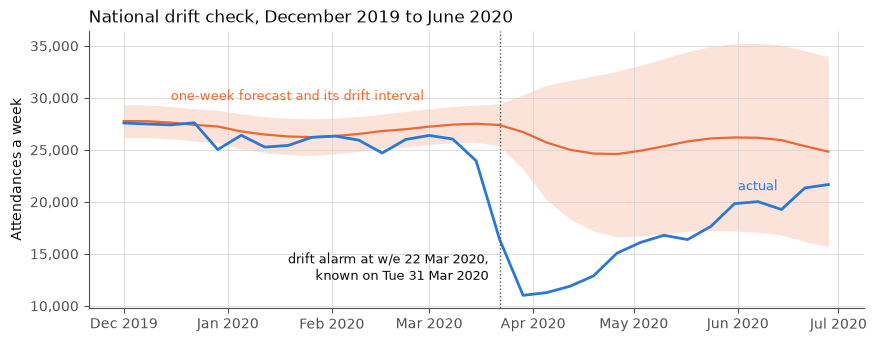

In [19]:
span = np.flatnonzero((weeks >= "2019-12-01") & (weeks <= "2020-06-28"))
point = nat["issued"][span - 1, 0]
half = nat["hw"][span]
actual = run.series["Scotland"][span]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(
    weeks[span], point - half, point + half, color=ORANGE, alpha=0.18, lw=0
)
ax.plot(weeks[span], point, color=ORANGE, lw=1.6)
ax.plot(weeks[span], actual, color=BLUE, lw=2)
alarm = pd.Timestamp("2020-03-22")
ax.axvline(alarm, color=MUTED, lw=1, ls=":")
ax.annotate(
    "drift alarm at w/e 22 Mar 2020,\nknown on Tue 31 Mar 2020",
    (alarm, 12500),
    xytext=(-8, 0),
    textcoords="offset points",
    ha="right",
    color=INK,
    fontsize=9,
)
ax.text(
    weeks[span][2],
    point[2] + half[2] + 600,
    "one-week forecast and its drift interval",
    color=ORANGE,
    fontsize=9,
)
late = int(np.flatnonzero(weeks[span] == pd.Timestamp("2020-06-07"))[0])
ax.text(
    weeks[span][late],
    actual[late] + 1100,
    "actual",
    color=BLUE,
    ha="center",
    fontsize=9,
)
ax.set_title(
    "National drift check, December 2019 to June 2020", loc="left", color=INK
)
ax.set_ylabel("Attendances a week")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %Y"))
fig.savefig(FIGURES / "drift_march_2020.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
g3 = ev.g3(run)
print(
    f"National drift alarm: w/e {g3['first_alarm_2020']}, known {g3['known']}"
)
display(pd.DataFrame(g3["national_episodes"]))
primaries = ev.primaries(run, NAMES)
print(
    f"{primaries['total_switches']} switches of primary across "
    f"{primaries['series_switched']} series; to each model: "
    f"{primaries['switches_by_target']}; primary at the end of the data: "
    f"{primaries['final']}"
)

National drift alarm: w/e 2020-03-22, known 2020-03-31


,first_breach,alarm,last_alarm,reset,first_direction,chosen_at_reset
0,2020-03-15,2020-03-22,2020-05-17,2020-07-12,down,4-week moving average
1,2023-01-08,2023-01-15,2023-01-15,2023-03-12,down,SA-MA
2,2025-12-21,2025-12-28,2026-01-18,2026-03-15,down,linear


55 switches of primary across 31 series; to each model: {'4-week moving average': 23, 'SA-MA': 19, 'linear': 8, 'seasonal naive': 5}; primary at the end of the data: {'4-week moving average': 11, 'SA-MA': 9, 'linear': 8, 'seasonal naive': 3}


In [21]:
replay = ev.replay_set(frame, run.weeks)
full = {o: tl.screen_at(run, o) for o in replay["by_origin"]}
print(
    "The full screen, all 30 hospitals and the national series, would send: "
    + ", ".join(f"{len(v)} at w/e {o}" for o, v in full.items())
)
screen = [e for v in full.values() for e in v if e.hospital in REPLAY]
briefs = pd.DataFrame(
    [
        {
            "origin": f"{e.as_of:%d %b %Y}",
            "released": f"{e.release_date:%a %d %b %Y}",
            "hospital": e.name,
            "brief": e.kind,
            "demand level": e.level,
            "level from": e.level_source,
            "latched since": e.latched_since,
            "breach": e.breach_direction,
        }
        for e in screen
    ]
)
demand = sum(e.kind == "demand" for e in screen)
print(
    f"Pre-run check: {replay['total']} briefs, {replay['by_source']}; "
    f"the sixth "
    f"origin by its rule is w/e {replay['sixth_origin']}; at least one brief "
    f"comes from a flag: {demand >= 1}"
)
quiet = [o for o, v in replay["by_origin"].items() if not v["briefs"]]
print("Origins with no brief:", ", ".join(quiet))
briefs

The full screen, all 30 hospitals and the national series, would send: 2 at w/e 2019-10-06, 4 at w/e 2019-12-08, 1 at w/e 2020-03-15, 12 at w/e 2020-03-22, 4 at w/e 2021-06-13, 6 at w/e 2023-04-09
Pre-run check: 7 briefs, {'latch': 4, 'demand': 2, 'surge': 1}; the sixth origin by its rule is w/e 2023-04-09; at least one brief comes from a flag: True
Origins with no brief: 2019-12-08, 2020-03-15


,origin,released,hospital,brief,demand level,level from,latched since,breach
0,06 Oct 2019,Tue 15 Oct 2019,Royal Infirmary of Edinburgh at Little France,surge,2,surge,2019-09-29,upward
1,22 Mar 2020,Tue 31 Mar 2020,Queen Elizabeth University Hospital,latch,1,held,2020-03-22,downward
2,22 Mar 2020,Tue 31 Mar 2020,Royal Infirmary of Edinburgh at Little France,latch,1,held,2020-03-22,downward
3,22 Mar 2020,Tue 31 Mar 2020,Ninewells Hospital,latch,1,held,2020-03-22,downward
4,22 Mar 2020,Tue 31 Mar 2020,Scotland,latch,1,held,2020-03-22,downward
5,13 Jun 2021,Tue 22 Jun 2021,Ninewells Hospital,demand,2,flag,None,NaN
6,09 Apr 2023,Tue 18 Apr 2023,Lorn & Islands Hospital,demand,2,flag,None,NaN


In [22]:
records = []
for e in screen:
    rec = tl.get_track_record(
        run, tl.TrackRecordRequest(hospital=e.hospital, as_of=e.as_of)
    )
    records.append(
        {
            "origin": f"{e.as_of:%d %b %Y}",
            "hospital": e.name,
            "past outlook flags": rec.flags,
            "borne out": rec.borne_out,
            "unflagged outlooks": rec.unflagged,
            "unflagged that turned busy, %": (
                None
                if rec.unflagged_busy_pct is None
                else round(rec.unflagged_busy_pct, 1)
            ),
        }
    )
print(
    "The track record each brief would quote, from outlooks whose weeks "
    "were all released by its origin"
)
pd.DataFrame(records)

The track record each brief would quote, from outlooks whose weeks were all released by its origin


,origin,hospital,past outlook flags,borne out,unflagged outlooks,"unflagged that turned busy, %"
0,06 Oct 2019,Royal Infirmary of Edinburgh at Little France,4,4,58,34.5
1,22 Mar 2020,Queen Elizabeth University Hospital,15,10,71,14.1
2,22 Mar 2020,Royal Infirmary of Edinburgh at Little France,5,4,73,37.0
3,22 Mar 2020,Ninewells Hospital,0,0,86,30.2
4,22 Mar 2020,Scotland,9,5,77,15.6
5,13 Jun 2021,Ninewells Hospital,0,0,136,21.3
6,09 Apr 2023,Lorn & Islands Hospital,21,13,208,23.6


In [23]:
sensitivity = ev.sensitivity(wide)
print(
    "Share of hospital outlooks at each demand level, with the simulated "
    "capacity at three percentiles"
)
sensitivity.round(1)

Share of hospital outlooks at each demand level, with the simulated capacity at three percentiles


,capacity_percentile,scope,outlooks,level_1_pct,level_2_pct,level_3_pct,level_4_pct,flag_rate_unlatched_pct
0,80,all years,12990,81.8,17.8,0.1,0.2,18.2
1,80,steady years,8310,77.4,22.1,0.2,0.3,22.2
2,90,all years,12990,91.6,8.2,0.1,0.1,8.3
3,90,steady years,8310,90.0,9.7,0.1,0.2,9.6
4,95,all years,12990,95.4,4.5,0.0,0.1,4.4
5,95,steady years,8310,94.9,5.0,0.1,0.1,4.8


## 5. Agents: Investigator and Reviewer

The screen is code: it sends a hospital to the agents when it is flagged, its surge or held level
is 2 or more, or its drift latch is set, and nothing else reaches them. The Investigator drafts the
demand brief through five read-only typed tools, each as of the origin, following the tool-use
pattern of ReAct, reasoning interleaved with tool calls (Yao et al., 2023). It never sets the level:
its draft has no field for one, so code copies the rule's level into every brief (G5, enforced by
schema).

**What the code proves about each figure** (D-SAFE-19). Code writes every figure, and what that
figure is. The Investigator cites each figure with the tool call that returned it and its measure,
such as a forecast, a range end, an actual or a back-test error, with its model, release horizon
and week. Its text holds only a placeholder for each, such as `{F1}`, and code writes the value in
with its label: "1,120 attendances (SA-MA forecast, release horizon 1, w/e 27 Jun 2021)". The words
around the placeholders name no number, model, release horizon, week, hospital or level; tokens
that code writes name those, such as `{PRIMARY}`, `{WEEK1}`, `{HOSPITAL}` and `{LEVEL}`. Pydantic
validators refuse a draft that breaks these rules, naming every problem at once. The Reviewer's
code check then proves three things before any language model reads the brief:

- each cited figure is what its tool call returned: its value within rounding, and its measure,
  model, release horizon, week and unit, for the same hospital and origin;
- the brief states the primary model's forecast, its hospital's own back-test error and its track
  record, each a cited figure from its tool;
- the level is the rule's.

So each number the manager reads is a tool's value, written beside its true label. The code does
not prove what a sentence says about a figure, such as calling an actual a forecast. The Reviewer
judges that, and so can the duty manager, who sees every label.

Only then does a language model check the wording, after a code screen for the words the MHRA lists
as indicative of a device. A failure gets one retry, with every problem named. A brief that fails
again reaches the manager marked "not verified, do not act", each problem marked where it stands,
and can never be approved (G4). A failed model call is recorded and replayed like any reply. A
Reviewer whose call fails is asked once more, and if it still gives no verdict the brief ends "not
verified", counted apart by that cause.

I adapted the model gateway with its recordings and exact replay, the typed tools, the approval
queue and the audit log from Agentic AI Systems. The model backend is one value in `config.json`:
`local`, the default, is Ollama on this machine with the model pinned by digest; `frontier`, the
Claude API, runs only with a stated case from the adequacy test (D-FRAME-03), with its key read
from the git-ignored `.env` alone.

**No language model runs in this notebook.** Every model reply in sections 5 to 7 is read from the
live run's recordings in `recordings/`; a missing or changed recording stops the notebook.

In [24]:
settings = cf.load_config("config.json")
HOLIDAYS = "bank-holidays_20261024.json"
holidays = dt.load_bank_holidays(DATA / HOLIDAYS, manifest[HOLIDAYS].sha256)
config_text = Path("config.json").read_text(encoding="utf-8")
if settings.llm_backend == "local":
    local = settings.local
    print(
        f"Model backend: local, {local.model}, pinned by digest "
        f"{local.digest[:12]}, temperature {local.temperature:g}, reasoning "
        f"effort {local.reasoning_effort}, at {local.endpoint}"
    )
else:
    print(
        f"Model backend: frontier, {settings.frontier.model}, temperature "
        f"{settings.frontier.temperature}; it cannot be pinned by digest"
    )
print(
    f"Frontier backend, only with a stated case: {settings.frontier.model}; "
    "its key is read from the git-ignored .env alone, and config.json names "
    f"its variable, {settings.frontier.api_key_env}, and holds no secret: "
    f"{not cf.secret_like(config_text)}"
)
print("What the agent writes:", ", ".join(br.BriefDraft.model_fields))
print(
    "What code sets:",
    ", ".join(
        f
        for f in br.DemandBrief.model_fields
        if f not in br.BriefDraft.model_fields
    ),
)
attempt = {f: "Some text." for f in br.TEXT_FIELDS if f != "watch_points"}
attempt.update(watch_points=["Check cover."], cited_figures=[], level=3)
try:
    br.BriefDraft.model_validate(attempt)
except ValidationError as exc:
    error = exc.errors()[0]
    print(
        f"A draft that sets its own level is refused: {error['type']} on "
        f"{error['loc'][0]!r}"
    )
del attempt["level"]
attempt["summary"] = "Expect 1,120 attendances."
try:
    br.BriefDraft.model_validate(attempt)
except ValidationError as exc:
    print(
        "A draft that writes a figure itself is refused:",
        br.problems_of(exc)[0],
    )

Model backend: local, nemotron-3.5-lightning:30b-a3b, pinned by digest e7a64ff15fb1, temperature 0, reasoning effort low, at http://localhost:11434/v1
Frontier backend, only with a stated case: claude-sonnet-5-5; its key is read from the git-ignored .env alone, and config.json names its variable, ANTHROPIC_API_KEY, and holds no secret: True
What the agent writes: summary, expected_range, model_agreement, backtest_error, track_record, watch_points, cited_figures
What code sets: brief_id, hospital, name, week, release_date, kind, level, level_source, level_meaning, drift_alarm, latched_since, breach_direction, primary, backend, model, model_digest
A draft that sets its own level is refused: extra_forbidden on 'level'
A draft that writes a figure itself is refused: summary: 1,120: write each figure as its placeholder, such as {F1}; code writes the number and what it is


**The safeguards shown acting, with a scripted stand-in.** Before the live run, a scripted stand-in
plays the model's part for Ninewells Hospital at w/e 13 Jun 2021, so the safeguards can be seen
acting with no model and no GPU. Nothing it says is a model's output: its drafts cite only true tool
values, written as placeholders that code fills in with their labels, and the planted ones add a
figure or a date no tool returned. It goes through the same graph, queue and coordinator as the live
run, and writes nothing in the repository.

In [25]:
shown = dm.safeguards(run, holidays, settings)
print(shown.label)
first = shown.caught.attempts[0]
print(
    "1. A figure planted by code in the first readable draft, as the designed "
    f"failure plants it. Caught at that figure by the code check: "
    f"{shown.caught.planted_caught}"
)
for failure in first.check.failures:
    print(f"   {failure.field}: {failure.reason}")
print(
    f"   After the one retry: {shown.caught.status}, in "
    f"{len(shown.caught.attempts)} attempts"
)
print(f"2. A brief planted twice: {shown.refused.status}.")
print(f"   An approval is refused: {shown.refusal}")
print("3. A manager's edit that fails the code check comes back marked:")
for line in shown.failed_edit.splitlines():
    if "NOT VERIFIED" in line:
        print(f"   {line}")
note = shown.notified.drafts[0]
print(
    f"4. A drafted notification with a planted date, {shown.planted_date}. "
    f"Caught before the outbox: {not note.check.passed}"
)
for failure in note.check.failures:
    print(f"   {failure.reason}")
print(shown.notified.summary())

Scripted stand-in: nothing it says is a model's output.
1. A figure planted by code in the first readable draft, as the designed failure plants it. Caught at that figure by the code check: True
   cited_figures[7]: 1535 is not SA-MA's forecast at release horizon 1 in T1
   After the one retry: verified, in 2 attempts
2. A brief planted twice: not verified.
   An approval is refused: demo-refused is not verified, do not act: it can never be approved
3. A manager's edit that fails the code check comes back marked:
   NOT VERIFIED, DO NOT ACT: it can never be approved.
   Summary: SA-MA (the primary model) forecasts 1,120 attendances (SA-MA forecast, release horizon 1, w/e 27 Jun 2021) for w/e 27 Jun 2021. Expect [[NOT VERIFIED: 1,450 attendances (SA-MA forecast, release horizon 1, w/e 27 Jun 2021)]].
4. A drafted notification with a planted date, 25 Jun 2021. Caught before the outbox: True
   10: write each figure as its placeholder, such as {F1}; code writes the number and what it is
  

### Live recordings: produced here by the main session

**Marker.** The live run is not part of this notebook. It is produced by the main session, and
every cell below replays it. From the repository root, with Ollama serving
`nemotron-3.5-lightning:30b-a3b` at its pinned digest and `nvidia-smi` read first:

    python -m ae_escalation.live briefs --label round1

It checks the digest, keeps a copy of the prompts in `recordings/local/round1/prompts/`, runs the
seven replay briefs and the designed failure, and records every model call, failed calls included,
in `recordings/local/round1/`. The run's budget, 840 seconds, holds for the whole run: it is checked
before every model call, no call runs past it, and a resumed run carries the time already spent. A
run that stops says what it completed, and the same command with `--resume` replays the recorded
calls, then carries on live in the budget left. It writes the adequacy form beside the recordings,
and the scores sheet in `approvals/`, for the main session's reviewer. Once the reviewer has scored
them:

    python -m ae_escalation.live adequacy --label round1

records the adequacy test in `approvals/` and, only when the verdict sends the set to approval,
releases the approval queue, `approvals/queue_local_round1.csv`, with a pre-filled edit file for
each brief. The round comes from the records already written: a second round, after the one bounded
prompt-tuning round, takes a new label, and there is no third. The frontier backend runs once, only
with the stated case that second round records, under the same label and on the prompts that label
kept, and `live choose` then records the approver's choice of set. After the approver's decisions
are saved as `approvals/decisions_local_round1.csv`:

    python -m ae_escalation.live notify --label round1

The Reviewer checks the wording of any edit, and the coordinator drafts the notifications for the
approved briefs, each recorded in the same folder and written to `outbox/`, never sent.

In [26]:
# Every live run recorded, by label and backend, and the set that goes to
# approval: the approver's chosen set, else the local set whose record sends
# it to approval, else the last label.
labels = sorted(
    {p.parent.name for p in Path("recordings").glob("*/*/briefs.jsonl")}
)
labels = labels or ["round1"]
sets = {
    (label, backend): rp.Paths.under(Path("."), backend, label)
    for label in labels
    for backend in ("local", "frontier")
    if rp.Paths.under(Path("."), backend, label).briefs.exists()
}
choices = sorted(Path("approvals").glob("set_choice_*.md"))
sent = [
    label
    for label in labels
    if rp.Paths.under(Path("."), "local", label).adequacy_record.exists()
    and "Goes to approval: yes"
    in rp.Paths.under(Path("."), "local", label).adequacy_record.read_text(
        encoding="utf-8"
    )
]
if choices:
    choice = choices[-1]
    LABEL = choice.stem.removeprefix("set_choice_")
    text = choice.read_text(encoding="utf-8")
    chosen = "frontier" if "the frontier set" in text else "local"
else:
    LABEL = sent[-1] if sent else labels[-1]
    choice = Path("approvals") / f"set_choice_{LABEL}.md"
    chosen = "local"
paths = rp.Paths.under(Path("."), chosen, LABEL)
chosen_settings = settings.model_copy(update={"llm_backend": chosen})
recorded = ", ".join(f"{label} ({backend})" for label, backend in sets)
print(
    f"Sets recorded: {recorded or 'none yet'}; the set that goes to "
    f"approval: {LABEL}, {chosen}"
)

Sets recorded: none yet; the set that goes to approval: round1, local


In [ ]:
# Every recorded set is replayed and reported, each label and each backend,
# so the first round's evidence stays in view after the tuning round (build
# spec, section 2, item 5); the chosen set goes on to approval.
replayed = {
    (label, backend): rp.run_set(
        run,
        holidays,
        settings.model_copy(update={"llm_backend": backend}),
        p,
        live=False,
    )
    for (label, backend), p in (sets or {(LABEL, chosen): paths}).items()
}
result = replayed[(LABEL, chosen)]
print(f"Pre-run check: {result.check}")
pd.DataFrame(
    [
        {
            "label": label,
            "set": backend,
            "brief": o.run_id,
            "hospital": NAMES[o.hospital],
            "origin": f"{o.origin:%Y-%m-%d}",
            "kind": o.entry.kind,
            "demand level": o.entry.level,
            "status": o.status,
            "not verified because": o.cause or "",
            "attempts": len(o.attempts),
            "model": o.model,
            "model calls": len(o.calls),
            "failed calls": sum(bool(c.error) for c in o.calls),
            "all replayed": all(c.replayed for c in o.calls),
        }
        for (label, backend), r in replayed.items()
        for o in r.outcomes
    ]
)

In [ ]:
for (label, backend), r in replayed.items():
    print(f"The {backend} set, {label}, each brief as the manager sees it")
    print()
    for o in r.outcomes:
        print(o.display())
        print()

In [ ]:
for (label, backend), r in replayed.items():
    planted = r.planted
    print(
        f"The designed failure, {backend} set, {label}, {planted.run_id}: a "
        "figure planted by code in the Investigator's first readable draft, "
        f"in attempt {planted.planted_attempt}. Caught at the planted figure "
        f"by the code check: {planted.planted_caught}"
    )
    attempt = next((a for a in planted.attempts if a.planted), None)
    for failure in attempt.check.failures if attempt and attempt.check else []:
        print(f"   {failure.field}: {failure.reason}")
    print(f"After the one retry: {planted.status}")

In [ ]:
for (label, backend), r in replayed.items():
    same = all(
        o.brief is None or o.brief.level == o.rule_level for o in r.outcomes
    )
    causes = [o.cause for o in r.outcomes if o.status == "not verified"]
    by_cause = {c: causes.count(c) for c in sorted(set(causes))}
    print(
        f"The {backend} set, {label}. G5, the level in every brief equals the "
        f"rule's: {same}. G4 events, briefs marked not verified: "
        f"{len(causes)}, by cause {by_cause}"
    )

In [ ]:
for label, backend in replayed:
    record = rp.Paths.under(Path("."), backend, label).adequacy_record
    if record.exists():
        print(record.read_text(encoding="utf-8"))
if choice.exists():
    print(choice.read_text(encoding="utf-8"))

## 6. Approval and coordination

Each verified brief goes to the approval queue. The approver approves, edits or rejects it with
initials and a timestamp, and records which of the six approval criteria it met; the criteria were
written before any brief existed. Only a verified brief can be approved. Every edit re-runs the
code figure check, the device-word screen and the Reviewer's wording check, and an edit that fails
comes back marked "not verified, do not act", never to the Investigator. Code marks an edit factual
when it changes a cited figure, or a figure, date, level or hospital in the text, and the approver
may also declare one.

In the spot check one person plays three roles: the approver; the unscheduled-care lead, who owns
the thresholds and approves each latch reset; and the analytics lead, who re-selects the primary
model at each reset. The clinical safety reviewer's sign-off is not exercised, because there is no
live use.

The coordinator is code. It sets the staffing actions for the level, assigns each to a role, sets
its reply deadline, tracks it and escalates it when the deadline passes. The actions are
illustrative, on the structure of OPEL Appendix F only: actions by level with an owner each. The
language model drafts only each notification's wording, under the same token rules as a brief:
every figure is a placeholder that code writes with its label, and code writes the hospital,
level, weeks and deadline. Before the outbox, Pydantic allows only figures the approved brief
states, none of them a past week's actual, each for the action's weeks or for no one week. The clock
runs in UK time, Europe/London. Notifications go to an outbox file and are never sent, and the
acknowledgements are simulated.

In [27]:
pd.DataFrame(
    [{"criterion": c.name, "met when": c.test} for c in ap.CRITERIA],
    index=pd.RangeIndex(1, 7, name="#"),
)

,criterion,met when
#,,
1,Figures correct,Every figure matches its tool result.
2,Uncertainty stated,"The range, the hospital's own back-test error and its track record are given."
3,Model disagreement named,"Where the forecasts disagree, the brief says so, and says which to trust less and why."
4,The level's meaning stated,"Demand for the time of year, not pressure, need or priority."
5,Watch points actionable,Each names something a manager can check or do this week.
6,No clinical instruction,Nothing reads as an instruction to a clinician.


In [28]:
hours = settings.coordinator.reply_deadline_hours
actions = pd.DataFrame(
    [
        {
            "level": level,
            "action": a.code,
            "task": a.task,
            "owner": a.owner,
            "escalated to": co.ESCALATE_TO[a.owner] or "no role above",
            "reply within, hours (assumed)": hours[level],
        }
        for level in (2, 3, 4)
        for a in co.actions_for(level)
    ]
).set_index(["level", "action"])
print(
    "Level 1 sets no staffing action. The actions are illustrative, and the "
    "deadlines and the replay clock's 10:00 start, UK time, on release day "
    "are assumed."
)
actions

Level 1 sets no staffing action. The actions are illustrative, and the deadlines and the replay clock's 10:00 start, UK time, on release day are assumed.


task  \
level action                                                                                                                                          
2     check-cover                                                          Check whether extra shifts or bank staff are needed for the weeks ahead.   
      hold-leave                                                Hold new leave requests for the weeks ahead until the duty manager's check is done.   
3     check-cover                                                          Check whether extra shifts or bank staff are needed for the weeks ahead.   
      hold-leave                                                Hold new leave requests for the weeks ahead until the duty manager's check is done.   
      request-bank                                                                                Ask the staff bank for cover for the weeks ahead.   
4     check-cover                                                          Check whether extra shifts or bank staff are needed for the weeks ahead.   
      hold-leave                                                Hold new leave requests for the weeks ahead until the duty manager's check is done.   
      request-bank                                                                                Ask the staff bank for cover for the weeks ahead.   
      inform-lead   Tell the unscheduled-care lead, who decides on any further front-door cover, about the shifts and bank staff already requested.   

                                    owner           escalated to  reply within, hours (assumed)  
level action                                                                                     
2     check-cover            duty manager  unscheduled-care lead                             48  
      hold-leave         rota coordinator           duty manager                             48  
3     check-cover            duty manager  unscheduled-care lead                             24  
      hold-leave         rota coordinator           duty manager                             24  
      request-bank      staff bank office           duty manager                             24  
4     check-cover            duty manager  unscheduled-care lead                             12  
      hold-leave         rota coordinator           duty manager                             12  
      request-bank      staff bank office           duty manager                             12  
      inform-lead   unscheduled-care lead          no role above                             12

In [ ]:
queue = rp.queue_with_decisions(result, paths, settings=chosen_settings)
for refusal in queue.refusals:
    print(f"Refused, and logged: {refusal['reason']}")
pd.DataFrame(
    [
        {
            "brief": i.brief_id,
            "state": i.state,
            "decisions": "; ".join(
                f"{d.action} by {d.initials} at {d.decided_at:%d %b %Y %H:%M}"
                f", {d.criteria.count()} of 6 criteria met"
                + (", factual edit" if d.factual_edit else "")
                for d in i.decisions
            ),
        }
        for i in queue.items()
    ]
)

In [ ]:
print("G4:", queue.g4())
print("G6:", queue.g6())

In [ ]:
done = rp.coordinate_approved(queue, chosen_settings, paths, live=False)
for d in done:
    print(d.brief_id)
    print(d.summary())
    print()

## 7. The replay set

The replay set is the five named series at the six origins: the probe's five and the sixth found by
the rule written before the search. The pre-run check in section 4 counted its briefs before any
agent ran: 7, of which 4 latch, 1 surge and 2 demand. Every rule that picks from the set is code
applied to the built set, so nothing is chosen after a brief has been read:

- the second reader's four: the demand brief, first by origin; the surge brief; the national latch
  brief; and the latch brief of the smallest hospital latched at w/e 22 Mar 2020;
- the template comparison's two weeks: the national latch week, w/e 22 Mar 2020, and the demand
  week, the first demand brief by origin;
- the designed failure: a second run of the demand week's brief, whose first readable draft gets a
  figure no tool returned, planted by code. It counts as caught only when the code check fails at
  that figure.

In [29]:
entries = rp.replay_entries(run)
four = rp.reader_b_four(entries, rp.sizes(run))
weeks = rp.template_weeks(entries)
pd.DataFrame(
    [
        {
            "brief": rp.run_id(e),
            "origin": f"{e.as_of:%d %b %Y}",
            "released": f"{e.release_date:%a %d %b %Y}",
            "hospital": e.name,
            "kind": e.kind,
            "demand level": e.level,
            "second reader": "yes" if e in four else "",
            "template week": next((w for w, x in weeks.items() if x == e), ""),
        }
        for e in entries
    ]
)

,brief,origin,released,hospital,kind,demand level,second reader,template week
0,20191006-S314H,06 Oct 2019,Tue 15 Oct 2019,Royal Infirmary of Edinburgh at Little France,surge,2,yes,
1,20200322-Scotland,22 Mar 2020,Tue 31 Mar 2020,Scotland,latch,1,yes,national latch week
2,20200322-S314H,22 Mar 2020,Tue 31 Mar 2020,Royal Infirmary of Edinburgh at Little France,latch,1,,
3,20200322-T101H,22 Mar 2020,Tue 31 Mar 2020,Ninewells Hospital,latch,1,yes,
4,20200322-G405H,22 Mar 2020,Tue 31 Mar 2020,Queen Elizabeth University Hospital,latch,1,,
5,20210613-T101H,13 Jun 2021,Tue 22 Jun 2021,Ninewells Hospital,demand,2,yes,demand week
6,20230409-C121H,09 Apr 2023,Tue 18 Apr 2023,Lorn & Islands Hospital,demand,2,,


**The template brief.** Its fields were fixed in the build spec before any brief existed, so the
code that fills it does not decide the comparison. It is a fixed fill-in-the-blanks text with no
free text: the level and its meaning, the four simple models' forecasts with their ranges, the
hospital's own back-test error, the track record, the drift status and one watch point chosen by
rule. Code fills each blank from the same tool results the Investigator uses, so it is never sent
to the Reviewer. It prints no calendar flag, and it never ranks the models or says which to trust
less.

In [30]:
templates = {w: tp.template_brief(run, e) for w, e in weeks.items()}
for week, t in templates.items():
    print(f"The template brief, {week}:")
    print(t.text())
    print()

The template brief, national latch week:
Scotland, week ending 22 Mar 2020, released Tue 31 Mar 2020

Demand level 1, from the flag held from the week before the alarm (held).
The demand level shows demand unusually high for the time of year. It is not pressure, need or priority.

Forecasts, with their 80% and 95% ranges:
| Model | Release horizon 1, w/e 05 Apr 2020 | Release horizon 2, w/e 12 Apr 2020 | Release horizon 3, w/e 19 Apr 2020 | Release horizon 4, w/e 26 Apr 2020 |
|---|---|---|---|---|
| seasonal naive | 26,175 (80%: 25,502 to 28,642; 95%: 23,864 to 29,450) | 26,609 (80%: 25,924 to 29,117; 95%: 24,260 to 29,938) | 28,754 (80%: 28,014 to 31,464; 95%: 26,216 to 32,351) | 29,573 (80%: 28,812 to 32,360; 95%: 26,962 to 33,273) |
| 4-week moving average | 23,194 (80%: 22,041 to 24,223; 95%: 21,250 to 24,809) | 23,194 (80%: 22,046 to 24,334; 95%: 21,203 to 24,927) | 23,194 (80%: 21,899 to 24,553; 95%: 21,145 to 25,315) | 23,194 (80%: 21,837 to 24,571; 95%: 21,041 to 25,317) |
| l

In [ ]:
# The pairs as the raters see them, in an order hidden from them, and with
# no line saying which backend wrote the agent's brief.
briefs = {o.run_id: o for o in result.outcomes}
key = {}
for week, e in weeks.items():
    order = tp.blind_order(week, seed=settings.seeds.template_order)
    key[week] = dict(zip("AB", order))
    texts = {
        "agent": tp.rater_view(briefs[rp.run_id(e)]),
        "template": templates[week].text(),
    }
    for label, who in key[week].items():
        print(f"{week}, Text {label}")
        print(texts[who])
        print()
print("The order, kept from the raters until they finished:", key)

## 8. Evaluation summary

**Goals, stated before the evaluation runs** (build spec, section 1a). No threshold moves from this
run onwards. G1, G3, G7 and G8 were settled by design tuning in the probes, so here they mainly check
that the build reproduces probe 7. G2 is measured here for the first time. G4, G5 and G6 concern the
demand briefs and are measured with them in Phase B.

| # | Goal | Met if |
|---|---|---|
| G1 | Forecasts a manager can plan with | National MAPE of the primary model as re-selected, at release horizons 1 to 4, on non-shock weeks, within 1 point of the best simple model at every release horizon |
| G2 | Honest uncertainty | 90% to 98% of national actuals inside the primary model's 95% brief range, at release horizons 1 to 4, on the same weeks as G1 |
| G3 | Shocks are caught | The national drift alarm known by Tue 31 Mar 2020; at most 1 false alarm a year nationally |
| G7 | Raised levels are rare in steady years | Under 10% of outlooks raised in every year except 2020 to 2022, with no floor |
| G8 | A flag tells a manager something | Outlook flags borne out at least twice as often as the outlook base rate, in all years and in the steady years, each; recall reported with no threshold |

Non-shock weeks are the target weeks outside the national drift episodes, first breach to last alarm.
The steady years are 2018 (from July), 2019 and 2023 to 2026. My reading of G2's range, which the
spec leaves open: the forecast times the central 95% of the primary's last 104 released ratios at
that horizon, the same errors the flag reads.

In [31]:
g1_table, g1_met = ev.g1(run)
g2_table, g2_met = ev.g2(run)
g7 = ev.g7(frame)
g8 = ev.g8(frame)
steady, every = g8["steady_years"], g8["all_years"]
over = {
    y: v["raised_pct_all"]
    for y, v in g7["by_year"].items()
    if y in g7["years_over_10_raised"]
}
verdicts = pd.DataFrame(
    [
        (
            "G1",
            "primary minus best simple model, points, RH1 to RH4: "
            + ", ".join(
                f"{v['primary_minus_best'][0]:+.2f}" for v in g1_table.values()
            ),
            g1_met,
        ),
        (
            "G2",
            "inside the 95% range, %, RH1 to RH4: "
            + ", ".join(f"{v['inside_pct']:.1f}" for v in g2_table.values()),
            g2_met,
        ),
        (
            "G3",
            f"alarm known {g3['known']}; national rising edges by year "
            f"{g3['alarm_rising_edges']}",
            g3["met"],
        ),
        ("G7", f"over 10% in {over}", g7["met_as_worded"]),
        (
            "G8",
            f"{steady['ratio'][0]:.2f} times the base rate in the steady "
            f"years, {every['ratio'][0]:.2f} in all years",
            g8["met"],
        ),
    ],
    columns=["goal", "result", "met"],
).set_index("goal")
verdicts["verdict"] = verdicts["met"].map({True: "met", False: "not met"})
verdicts[["result", "verdict"]]

,result,verdict
goal,,
G1,"primary minus best simple model, points, RH1 to RH4: -0.18, -0.37, -0.55, -0.74",met
G2,"inside the 95% range, %, RH1 to RH4: 96.4, 95.9, 96.1, 95.7",met
G3,"alarm known 2020-03-31; national rising edges by year {2018: 0, 2019: 0, 2023: 1, 2024: 0, 2025: 1, 2026: 1}",met
G7,"over 10% in {2018: 10.4, 2023: 10.9, 2024: 11.7}",not met
G8,"2.54 times the base rate in the steady years, 3.67 in all years",met


In [32]:
print(
    "G1, national MAPE % on non-shock weeks, with the primary minus the best "
    "simple model and its 95% interval"
)
display(pd.DataFrame(g1_table).T)
blocks_table, blocks_met = ev.g1(run_blocks)
print(
    f"Sensitivity, SA-MA's index over 52-week blocks: G1 met {blocks_met}; "
    "primary minus best by release horizon: "
    + ", ".join(str(v["primary_minus_best"]) for v in blocks_table.values())
)
print("G2, national actuals inside the primary's 95% brief range")
pd.DataFrame(g2_table).T.astype({"n": int})

G1, national MAPE % on non-shock weeks, with the primary minus the best simple model and its 95% interval


,n,primary,4-week moving average,seasonal naive,SA-MA,best,primary_minus_best,within_1
RH1,441,"[4.04, 3.29, 4.99]",4.22,9.19,3.47,4-week moving average,"[-0.18, -0.65, 0.52]",True
RH2,441,"[4.52, 3.63, 5.59]",4.89,9.19,3.85,4-week moving average,"[-0.37, -0.85, 0.3]",True
RH3,441,"[4.94, 3.93, 6.15]",5.49,9.19,4.2,4-week moving average,"[-0.55, -1.05, 0.1]",True
RH4,441,"[5.31, 4.2, 6.62]",6.05,9.19,4.57,4-week moving average,"[-0.74, -1.22, -0.18]",True


Sensitivity, SA-MA's index over 52-week blocks: G1 met True; primary minus best by release horizon: [0.15, -0.34, 0.84], [-0.13, -0.62, 0.54], [-0.39, -0.89, 0.25], [-0.65, -1.16, -0.06]
G2, national actuals inside the primary's 95% brief range


,n,inside_pct
RH1,441,96.4
RH2,441,95.9
RH3,441,96.1
RH4,441,95.7


In [33]:
alarms, per_year = ev.hospital_false_alarms(run)
print(
    f"G3 nationally: alarm rising edges by steady year "
    f"{g3['alarm_rising_edges']}; new latch episodes "
    f"{g3['new_latch_episodes']}"
)
print(
    f"Beside it, at hospital level: {alarms['rising_edges'].sum()} alarm "
    f"rising edges across {len(alarms)} hospitals in the steady years, "
    f"{per_year:.2f} a hospital a year"
)
alarms.assign(name=alarms["site"].map(NAMES)).sort_values(
    "rising_edges", ascending=False
).head(8)

G3 nationally: alarm rising edges by steady year {2018: 0, 2019: 0, 2023: 1, 2024: 0, 2025: 1, 2026: 1}; new latch episodes {2018: 0, 2019: 0, 2023: 1, 2024: 0, 2025: 1, 2026: 0}
Beside it, at hospital level: 49 alarm rising edges across 30 hospitals in the steady years, 0.28 a hospital a year


,site,rising_edges,name
0,A111H,4,University Hospital Crosshouse
1,A210H,4,University Hospital Ayr
19,R103H,4,The Balfour
10,H103H,3,Caithness General Hospital
21,S314H,3,Royal Infirmary of Edinburgh at Little France
9,G513H,3,Royal Hospital for Children
22,S319H,3,Royal Hospital for Children and Young People
13,L106H,2,University Hospital Monklands


In [34]:
print(
    f"G7, share of hospital outlooks raised by the origin's year; without "
    f"March 2020 to March 2022: {g7['raised_overall']}"
)
pd.DataFrame(g7["by_year"]).T.astype({"hospital_weeks": int, "unlatched": int})

G7, share of hospital outlooks raised by the origin's year; without March 2020 to March 2022: {'without_covid_pct': 10.3, 'with_covid_pct': 8.4, 'flag_rate_unlatched_without_covid_pct': 9.9}


,hospital_weeks,unlatched,flag_rate_unlatched_pct,raised_pct_all,from_flag_pct,from_surge_pct,held_pct,latched_pct
2018,810,754,9.4,10.4,8.8,1.6,0.0,6.9
2019,1560,1457,8.0,9.9,7.4,1.4,1.0,6.6
2020,1560,1156,1.0,1.2,0.7,0.0,0.5,25.9
2021,1560,1543,4.4,4.4,4.4,0.0,0.0,1.1
2022,1560,1520,11.1,11.3,10.8,0.5,0.0,2.6
2023,1590,1518,11.2,10.9,10.7,0.2,0.0,4.5
2024,1560,1531,11.9,11.7,11.7,0.1,0.0,1.9
2025,1560,1511,7.4,7.3,7.2,0.1,0.0,3.1
2026,1230,1184,9.5,9.8,9.1,0.0,0.7,3.7


In [35]:
print(
    "G8, outlook flags: borne out against the outlook base rate, and "
    "recall, with 95% week-block intervals"
)
display(pd.DataFrame({k: g8[k] for k in ("steady_years", "all_years")}).T)
print(
    f"Sensitivity, SA-MA over 52-week blocks: steady-year ratio "
    f"{ev.g8(run_blocks.frame)['steady_years']['ratio']}"
)
by_year = ev.g8_by(frame, frame["year"])
by_year = by_year[by_year["group"] >= 2018].sort_values("group")
cols = [
    "group",
    "outlooks",
    "flags",
    "borne_out_pct",
    "base_rate_pct",
    "recall_pct",
    "ratio",
]
print("By the origin's year")
display(by_year[cols].round(2))
band = frame["series"].map(sizes["band"]).astype(object)
by_band = ev.g8_by(frame, band, steady_only=True)
print(
    "By hospital size band, steady years: rarity buys precision at the cost "
    "of recall"
)
by_band.set_index("group").loc[list(bt.SIZE_BANDS), cols[1:]].round(2)

G8, outlook flags: borne out against the outlook base rate, and recall, with 95% week-block intervals


,weeks,flags,flag_rate_pct,borne_out_pct,base_rate_pct,ratio,recall_pct
steady_years,7805,742,9.5,"[53.8, 45.3, 61.3]","[21.2, 17.4, 24.6]","[2.54, 2.19, 2.95]","[21.0, 17.2, 24.7]"
all_years,12024,989,8.2,"[58.3, 51.2, 64.7]","[15.9, 12.6, 19.3]","[3.67, 3.02, 4.59]","[24.7, 20.4, 29.2]"


Sensitivity, SA-MA over 52-week blocks: steady-year ratio [2.59, 2.25, 3.07]
By the origin's year


,group,outlooks,flags,borne_out_pct,base_rate_pct,recall_pct,ratio
0,2018,754,71,59.15,16.98,26.58,3.48
1,2019,1457,116,59.48,32.44,13.69,1.83
2,2020,1156,11,45.45,1.66,20.83,27.39
3,2021,1543,68,69.12,4.54,41.23,15.22
4,2022,1520,168,75.00,12.80,42.14,5.86
5,2023,1518,170,48.82,17.28,26.27,2.82
6,2024,1531,182,56.59,20.24,27.39,2.80
7,2025,1511,112,54.46,15.44,22.02,3.53
8,2026,1034,91,45.05,23.75,15.47,1.90


By hospital size band, steady years: rarity buys precision at the cost of recall


,outlooks,flags,borne_out_pct,base_rate_pct,recall_pct,ratio
group,,,,,,
under 300,1824,197,52.28,29.50,17.67,1.77
300 to 799,2086,223,52.91,22.76,21.77,2.33
"800 to 1,299",2347,127,52.76,15.45,16.34,3.41
"1,300 and over",1548,195,56.92,18.48,30.75,3.08


**The headline in its two units, each beside its own base rate.** An outlook flag means an unusually
busy week is likely somewhere in the next four, and is set beside the outlook base rate. A week flag
names one target week, and is set beside the week base rate. Precisions are never compared across the
two. Notice is counted in hospital-weeks counted once: a busy week is given notice when any flagged
unlatched outlook covered it, and by the stricter count only when the week's own flag did.

In [36]:
repeats = un.repeat_flags(run)
value = un.value_counts(run, NAMES)


def unit_row(scope):
    u = repeats["units"][scope]
    return {
        "outlook flags borne out, %": u["outlook_flag"]["precision_pct"][0],
        "outlook base rate, %": u["outlook_flag"]["base_rate_pct"][0],
        "week flags right, %": u["week_flag"]["precision_pct"][0],
        "week base rate, %": u["week_flag"]["base_rate_pct"][0],
    }


two_units = pd.DataFrame(
    {s: unit_row(s) for s in ("steady_years", "all_years")}
)
display(two_units)
weeks_steady = value["sites_target_weeks"]["steady_years"]
excess = weeks_steady["excess_over_capacity"]
print(
    f"Steady years, hospital-weeks counted once: "
    f"{weeks_steady['given_notice']} of "
    f"{weeks_steady['busy']} busy weeks given notice; "
    f"{weeks_steady['given_notice_strict']['weeks']} by the week's own flag; "
    f"{excess['flagged_and_busy']['total']:,.0f} of "
    f"{excess['all_busy']['total']:,.0f} extra patients in the weeks given "
    "notice"
)
typical = pd.DataFrame(
    {
        "typical steady year": value["plain"]["typical_steady_year"],
        "range": {
            k: tuple(v) for k, v in value["plain"]["typical_range"].items()
        },
    }
)
print("A typical steady year, the mean of 2019, 2023, 2024 and 2025")
typical

,steady_years,all_years
"outlook flags borne out, %",53.77,58.34
"outlook base rate, %",21.19,15.91
"week flags right, %",27.62,31.84
"week base rate, %",7.78,6.06


Steady years, hospital-weeks counted once: 280 of 713 busy weeks given notice; 197 by the week's own flag; 19,806 of 46,243 extra patients in the weeks given notice
A typical steady year, the mean of 2019, 2023, 2024 and 2025


,typical steady year,range
busy_weeks,142.50,"(101, 204)"
given_notice,57.00,"(42, 71)"
extra_patients_given_notice,4119.40,"(2140.4, 6834.2)"
missed,85.50,"(58, 143)"
extra_patients_missed,5049.55,"(2574.2, 9844.4)"
false_flags,66.00,"(47, 87)"
flags,145.00,"(112, 182)"
given_notice_week_ahead,49.00,"(31, 63)"
extra_patients_week_ahead,3568.60,"(1938.8, 6131.4)"


In [37]:
week = repeats["per_week"]["steady_years"]
rep, first = week["repeated"], week["first"]
print(
    f"Repeated week flags, steady years: right {rep['precision_pct']} % "
    f"against first week flags {first['precision_pct']} %. Clearly more "
    "precise by the rule stated before probe 9: "
    f"{repeats['clearly_more_precise']}, so the graduated response is: "
    f"{repeats['graduated_response']}"
)

Repeated week flags, steady years: right [29.22, 22.16, 35.81] % against first week flags [25.57, 20.73, 31.27] %. Clearly more precise by the rule stated before probe 9: False, so the graduated response is: drop


In [38]:
calibration = ev.calibration(frame)
per_week = calibration["steady_years"]["per_week"]
print(
    f"Steady years: each week's own stated chance averaged "
    f"{per_week['mean_stated']:.3f}, and {per_week['observed']:.1%} of those "
    f"weeks were busy. The flag's chance, the highest of four, against the "
    f"hospital's real-time busy share, Brier skill: "
    f"{calibration['steady_years']['skill_vs_real_time']:.3f}"
)
print("Reliability of each week's own stated chance, steady years")
pd.DataFrame(per_week["reliability"])

Steady years: each week's own stated chance averaged 0.162, and 8.9% of those weeks were busy. The flag's chance, the highest of four, against the hospital's real-time busy share, Brier skill: 0.128
Reliability of each week's own stated chance, steady years


,lo,hi,n,mean_p,observed
0,0.0,0.1,15345,0.033,0.031
1,0.1,0.2,5911,0.145,0.089
2,0.2,0.3,4182,0.245,0.120
3,0.3,0.4,2262,0.349,0.189
4,0.4,0.5,1717,0.443,0.210
5,0.5,0.6,963,0.543,0.232
6,0.6,0.7,468,0.645,0.286
7,0.7,0.8,231,0.744,0.329
8,0.8,0.9,110,0.847,0.409
9,0.9,1.0,31,0.931,0.645


In [39]:
months = ev.by_month(frame)
by_month = pd.DataFrame(months["steady_years"])
by_month.index.name = "month of the origin"
sept = repeats["units"]["september_outlook_flag_steady"]
print(
    f"September, steady years: {by_month.loc[9, 'flag_rate_pct']}% of "
    "outlooks "
    f"flagged; outlook flags borne out {sept['precision_pct'][0]:.1f}% "
    "against "
    f"{sept['base_rate_pct'][0]:.1f}% of unflagged September outlooks"
)
by_month

September, steady years: 12.8% of outlooks flagged; outlook flags borne out 40.5% against 14.9% of unflagged September outlooks


,flag_rate_pct,share_of_flags_pct,busy_rate_pct,borne_out_pct
month of the origin,,,,
1,6.6,5.1,23.0,50.0
2,15.6,11.6,24.9,51.2
3,6.3,5.9,20.5,47.7
4,10.3,8.6,26.7,37.5
5,11.7,9.7,23.3,50.0
6,4.9,4.4,20.4,57.6
7,7.3,7.1,27.2,71.7
8,12.5,12.4,32.0,69.6
9,12.8,12.0,18.2,40.4


In [40]:
pressure = ev.pressure_match(frame, wide, within4)
print(
    "Raised outlooks in their hospital's worst quarter of 4-hour weeks for "
    "the year, steady years: a weak link, not a pressure measure"
)
pd.Series(pressure, name="value", dtype=object).to_frame()

Raised outlooks in their hospital's worst quarter of 4-hour weeks for the year, steady years: a weak link, not a pressure measure


,value
weeks,8160
raised_pct,9.9
not_borne_out_pct_of_raised,45.6
raised_in_worst_quarter_pct,29.9
chance_pct,25.4
flags_in_worst_quarter_pct,29.8


In [41]:
by_site = ev.level_by_site(frame, sizes, NAMES)
named = ["S314H", "G107H", "G405H"]
shown_sites = pd.concat(
    [by_site.head(5), by_site[by_site["site"].isin(named)]]
).drop_duplicates("site")
print(
    "The demand level by site, steady years: the five most raised, with the "
    "three largest adult EDs beside them"
)
shown_sites.round(1)

The demand level by site, steady years: the five most raised, with the three largest adult EDs beside them


,site,name,mean_weekly,band,outlooks,raised_pct,flags,borne_out_pct,base_rate_pct
0,G513H,Royal Hospital for Children,1425.2,"1,300 and over",277,35.7,79,62.0,13.3
1,N121H,Royal Aberdeen Children's Hospital,342.7,300 to 799,277,26.0,71,42.3,26.7
2,R103H,The Balfour,146.3,under 300,277,21.3,50,60.0,47.2
3,H103H,Caithness General Hospital,188.2,under 300,277,19.5,40,77.5,31.7
4,Y146H,Dumfries & Galloway Royal Infirmary,679.9,300 to 799,277,18.8,52,75.0,20.0
5,G405H,Queen Elizabeth University Hospital,1909.7,"1,300 and over",277,16.6,46,65.2,29.6
22,S314H,Royal Infirmary of Edinburgh at Little France,2362.5,"1,300 and over",277,4.7,6,83.3,22.7
29,G107H,Glasgow Royal Infirmary,1602.1,"1,300 and over",277,0.0,0,NaN,8.7


In [42]:
sites_frame = frame[(frame["series"] != "Scotland") & frame["known"]]
screened = pd.DataFrame(
    {
        y: ev.screened_raise_borne_out(
            g["level"], g["source"], g["latched"], g["busy"]
        )
        for y, g in sites_frame.groupby("year")
        if y in ds.STEADY_YEARS
    }
).T.astype({"screened": int, "raise_borne_out": int})
print(
    "Of the hospital-weeks screened in each steady year, the share carrying "
    "a raise by the rule that was borne out"
)
screened.round(1)

Of the hospital-weeks screened in each steady year, the share carrying a raise by the rule that was borne out


,screened,raise_borne_out,pct
2018,127,54,42.5
2019,219,83,37.9
2023,242,86,35.5
2024,211,103,48.8
2025,161,63,39.1
2026,137,41,29.9


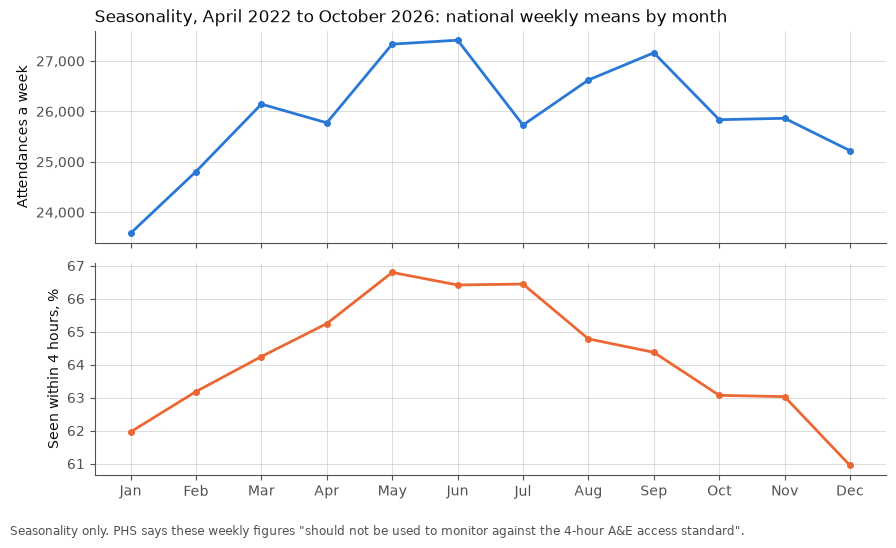

,attendances,within_4h_pct,over_12h
month,,,
1,23582.9,62.0,1923.6
2,24806.8,63.2,1575.3
3,26144.5,64.2,1403.7
4,25774.0,65.2,1194.5
5,27334.6,66.8,1113.6
6,27412.9,66.4,1122.8
7,25730.0,66.4,1014.4
8,26623.5,64.8,1200.3
9,27162.7,64.4,1333.3


In [43]:
profile = ev.month_profile(flagged)
month_names = pd.to_datetime(profile.index, format="%m").strftime("%b")
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
top.plot(
    month_names, profile["attendances"], color=BLUE, lw=2, marker="o", ms=4
)
top.set_ylabel("Attendances a week")
top.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
top.set_title(
    "Seasonality, April 2022 to October 2026: national weekly means by month",
    loc="left",
    color=INK,
)
bottom.plot(
    month_names, profile["within_4h_pct"], color=ORANGE, lw=2, marker="o", ms=4
)
bottom.set_ylabel("Seen within 4 hours, %")
fig.text(
    0.01,
    -0.04,
    'Seasonality only. PHS says these weekly figures "should not be used to '
    'monitor against the 4-hour A&E access standard".',
    color=MUTED,
    fontsize=8.5,
)
fig.tight_layout()
fig.savefig(
    FIGURES / "month_attendances_and_4_hours.png", dpi=150, bbox_inches="tight"
)
plt.show()
profile.round(1)

**In-sample.** The bands, the re-selection, SA-MA's two settings, the flag's setting and goals G1,
G3, G7 and G8 were all settled by design tuning on the same 2015 to 2026 data that scores them here.
Every figure in this section is in-sample. Before any go-live, the frozen design would run in shadow
mode on new weekly releases, with every brief written and logged and none acted on.

## 9. Limitations and what is simulated